# Part 7 of 7: Extension – Other Diseases and Other Crops

COMP7015 Group Project – Topic 1: Plant Disease Classification. The final models of notebooks 02–05 know four classes, so they force every photo into one of them. A phone photo of a leaf with another tomato disease, or of another crop, is still called healthy, early blight, leaf mold or spider mites. This notebook (Sections 23–30) adds two classes, **Other disease** and **Other crop**. It trains the three selected recipes on the six classes and on the four classes, repeats the robustness tests of notebook 05 and compares the two designs.

**Background removed.** Every model in this notebook trains and is tested on **background-removed photos** (PlantVillage `raw/segmented`: the leaf on black). Each PlantVillage folder is its own photo series with its own background, and notebook 05 showed that the four-class models partly classify the background. With many new folders, each with its own background, this shortcut would only grow. Without the background the models have to tell the classes apart by the leaf; the ViT of Section 15 reached 0.998 macro-F1 this way. To compare the designs fairly, the four-class models are also trained on background-removed photos, so the two designs differ only in their classes.

**One training seed.** To save training time, this notebook trains and evaluates with the first training seed only (62). Every number is a single run without a standard deviation. Notebooks 04–05 show a seed-to-seed spread of up to about 0.01 macro-F1 on the clean tomato test and much more under image changes, so small differences between the two designs should not be over-read.

| Question | Section |
|---|---|
| Which photos form the two new classes, and which are held out completely? | 23 |
| Training the selected CNN, ResNet18 and ViT on four and on six classes | 24 |
| Do the new classes cost accuracy on the tomato classes? | 25 |
| Are the six-class models more robust on the same tomato test leaves? | 26 |
| The left-out healthy series and PlantDoc field photos of the four tomato classes | 27 |
| Do the models refuse photos outside the four tomato classes, also of diseases and crops never seen in training? | 28 |
| Does the refusal survive image changes, and are the models calibrated? | 29 |
| Summary and discussion | 30 |

The notebooks run in order: `01_data` → `02_cnn_resnet` → `03_vit` → `04_test_evaluation` → `05_robustness` → `06_discussion` → `07_open_set`. This notebook needs the selected recipes of notebooks 02–03 and reuses the background-removed ViT of notebook 05. The shared code lives in the `plantdisease/` package; the design of the new classes is in `plantdisease/open_set.py`. Finished training runs and predictions are saved under `OUT_DIR/runs/` and reused.

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score

from plantdisease.backgrounds import (
    add_background_tests,
    image_changes,
    make_test_variants,
)
from plantdisease.config import DATA_CONFIG, PLANTDOC_CONFIG, TRAIN_CONFIG, out_path
from plantdisease.data import build_cache, field_records, load_segmented, prepare
from plantdisease.evaluate import (
    comparison_table,
    expected_calibration_error,
    mean_sd,
    seed_scores,
    shift_table,
    stable_errors,
    training_cost,
)
from plantdisease.experiments import load_final_models, open_set_name
from plantdisease.open_set import (
    CLASS_NAMES,
    FIELD_FOLDERS,
    NUM_CLASSES,
    OTHER_CROP,
    OTHER_DISEASE,
    TOMATO_LABELS,
    TRAIN_FOLDERS,
    download_open_set,
    held_out_records,
    out_of_scope_auroc,
    out_of_scope_field_records,
    prepare_open_set,
    rejected,
    rejection_threshold,
)
from plantdisease.plots import finish, grouped_bars
from plantdisease.train import predict_probs, run_seeds

# One training seed: the plantdisease helpers read this shared list, so shortening it in place
# limits training and evaluation in this notebook to the first seed (62)
TRAIN_CONFIG["seeds"][:] = TRAIN_CONFIG["seeds"][:1]

# The selected recipes (notebooks 02, 03), all trained on background-removed photos
FINAL_MODELS = [f"{n} + background-removed training" for n in load_final_models()]
OPEN_MODELS = [open_set_name(n) for n in FINAL_MODELS]  # the same, with six classes
PAIRS = list(zip(OPEN_MODELS, FINAL_MODELS, strict=True))  # (six-class, four-class)
ALL_MODELS = [*FINAL_MODELS, *OPEN_MODELS]
ARCHS = ["SE-CNN", "ResNet18", "ViT-B/16"]
DESIGN = dict.fromkeys(FINAL_MODELS, "4 classes") | dict.fromkeys(
    OPEN_MODELS, "6 classes"
)

data = prepare()  # four tomato classes: leaf-group split of notebook 01
download_open_set()  # raw/color and raw/segmented of the new and held-out folders
data6 = prepare_open_set(data)  # the same tomato photos and split + the two new classes
# background-removed photos, aligned with data.images / data6.images
SEG4, SEG6 = data.segmented[0], data6.segmented[0]

## 23. Data: Two New Classes

| Label | Photos for training, validation and test | Held out completely (test only, Section 28) |
|---|---|---|
| healthy, Early_blight, Leaf_Mold, Spider_mites | the photos, leaf ids and split of notebook 01 | `GH_HL` series, PlantDoc (Section 27) |
| **Other_disease** | four other tomato diseases: bacterial spot, Septoria leaf spot, target spot, yellow leaf curl virus | tomato late blight, tomato mosaic virus |
| **Other_crop** | 18 folders of 7 crops, healthy and diseased: apple, cherry, grape, peach, bell pepper, potato, strawberry | blueberry, corn (4 folders), orange, raspberry, soybean, squash |

- **The tomato classes are unchanged.** All four-class photos keep their leaf ids and split, so the 688 tomato test photos are the same as in notebooks 04–05. Four-class and six-class models of the same recipe and seed can therefore be compared directly.
- **About 1,000 photos per new class**, the size of the tomato classes, spread evenly over the source folders. Whole leaves with official leaf ids are drawn in random order, at most two photos per leaf, so the photos cover as many leaves as possible. The leaves of every folder are split 70/15/15 with the split seed, like the tomato classes, and no leaf id crosses two splits.
- **Leaf ids** come from `leaf-map.json`, with the two fixes of `database/REPORT.md`: the leaf map names apple black rot "Apple_Frogeye Spot", and the target-spot files were renamed after the leaf map was made.
- **Held out completely.** Two tomato diseases and six crops never appear in training. They test how the models treat a kind of photo that they have never seen (150 photos per folder, Section 28).
- **Only photos with a background-removed version** are used. Every photo of the selected folders has one; the corn common-rust photos lack the UUID prefix of their segmented files and are matched by name.

In [4]:
df6 = data6.df.assign(**{"class": lambda d: [CLASS_NAMES[c] for c in d.label]})

class_counts = (
    df6.groupby(["class", "split"])
    .size()
    .unstack()[["train", "val", "test"]]
    .reindex(CLASS_NAMES)
)
class_counts["All"] = class_counts.sum(axis=1)
class_counts["source folders"] = df6.groupby("class")["folder"].nunique()
class_counts["leaf ids"] = df6.groupby("class")["leaf_id"].nunique()
class_counts.loc["All"] = class_counts.sum()
class_counts.to_csv(out_path("open_set_class_counts.csv"))
display(class_counts)

new_photos = df6[df6.label >= OTHER_DISEASE]
folder_counts = new_photos.groupby(["class", "folder"]).agg(
    photos=("path", "size"), leaves=("leaf_id", "nunique")
)
folder_counts.T

split,train,val,test,All,source folders,leaf ids
class,,,,,,
healthy,699,152,148,999,1,250
Early_blight,699,152,148,999,1,250
Leaf_Mold,668,144,140,952,1,238
Spider_mites,1172,252,252,1676,1,419
Other_disease,704,152,144,1000,4,500
Other_crop,720,143,145,1008,18,505
All,4662,995,977,6634,26,2162


class          Other_crop                                             \
folder Apple___Apple_scab Apple___Black_rot Apple___Cedar_apple_rust   
photos                 56                56                       56   
leaves                 28                28                       28   

class                                                            \
folder Apple___healthy Cherry_(including_sour)___Powdery_mildew   
photos              56                                       56   
leaves              28                                       29   

class                                                       \
folder Cherry_(including_sour)___healthy Grape___Black_rot   
photos                                56                56   
leaves                                28                28   

class                                \
folder Grape___Esca_(Black_Measles)   
photos                           56   
leaves                           28   

class                                                                     ...  \
folder Grape___Leaf_blight_(Isariopsis_Leaf_Spot) Peach___Bacterial_spot  ...   
photos                                         56                     56  ...   
leaves                                         28                     28  ...   

class                                                                     \
folder Pepper,_bell___healthy Potato___Early_blight Potato___Late_blight   
photos                     56                    56                   56   
leaves                     28                    28                   28   

class                                                                  \
folder Potato___healthy Strawberry___Leaf_scorch Strawberry___healthy   
photos               56                       56                   56   
leaves               28                       28                   28   

class            Other_disease                              \
folder Tomato___Bacterial_spot Tomato___Septoria_leaf_spot   
photos                     250                         250   
leaves                     125                         125   

class                                                               
folder Tomato___Target_Spot Tomato___Tomato_Yellow_Leaf_Curl_Virus  
photos                  250                                    250  
leaves                  125                                    125  

[2 rows x 22 columns]

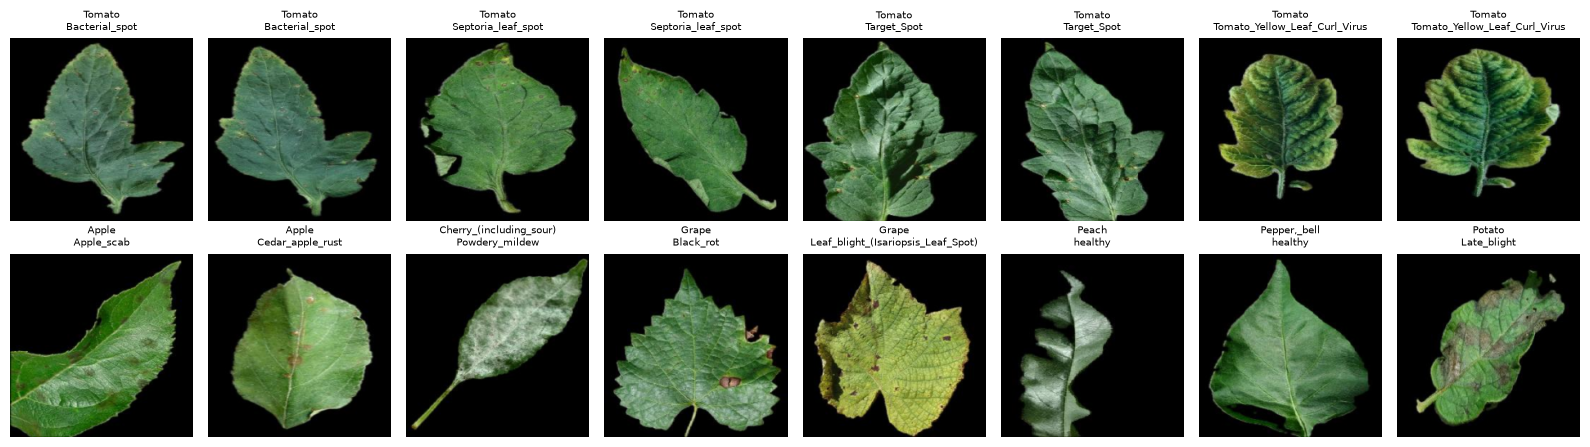

In [5]:
# Training input of the new classes: two background-removed photos of every Other_disease folder,
# one of eight Other_crop folders
examples = [
    df6.index[df6.folder == f][k] for f in TRAIN_FOLDERS[OTHER_DISEASE] for k in (0, 1)
] + [df6.index[df6.folder == f][0] for f in TRAIN_FOLDERS[OTHER_CROP][::2][:8]]
fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
for ax, i in zip(axes.ravel(), examples, strict=True):
    ax.imshow(SEG6[i].permute(1, 2, 0))
    ax.set_title(df6.folder[i].replace("___", "\n"), fontsize=7)
    ax.axis("off")
finish("open_set_examples.png")

### 23.1 How much does the background alone tell?

The random forest of Section 5.1 sees only the mean colour of the four image corners, now for six classes, trained on the training photos and evaluated on the validation photos. On the original photos the corners show the background; on the background-removed photos, which the models of this notebook see, they are mostly black.

In [6]:
def corner_features(images, size=24):
    # Mean colour of the four image corners: the background only, 12 numbers per photo.
    corners = [
        images[:, :, :size, :size],
        images[:, :, :size, -size:],
        images[:, :, -size:, :size],
        images[:, :, -size:, -size:],
    ]
    return np.concatenate([c.float().mean(dim=(2, 3)).numpy() for c in corners], 1)


y6_all = data6.labels.numpy()
y6_val = y6_all[data6.val_idx]
rows, recalls = {}, {}
for input_name, images in {
    "four image corners, original photos": data6.images,
    "four image corners, background removed": SEG6,
}.items():
    X_corners = corner_features(images)
    corner_pred = (
        RandomForestClassifier(
            n_estimators=200, random_state=DATA_CONFIG["split_seed"], n_jobs=-1
        )
        .fit(X_corners[data6.train_idx], y6_all[data6.train_idx])
        .predict(X_corners[data6.val_idx])
    )
    rows[input_name] = {
        "accuracy": accuracy_score(y6_val, corner_pred),
        "macro-F1": f1_score(y6_val, corner_pred, average="macro"),
    }
    recalls[input_name] = [
        (corner_pred[y6_val == c] == c).mean() for c in range(NUM_CLASSES)
    ]
majority = np.full(len(y6_val), np.bincount(y6_all[data6.train_idx]).argmax())
rows["always the largest class (reference)"] = {
    "accuracy": accuracy_score(y6_val, majority),
    "macro-F1": f1_score(y6_val, majority, average="macro"),
}
background_only = pd.DataFrame(rows).T
background_only.to_csv(out_path("open_set_background_only.csv"))
display(background_only.round(3))
pd.DataFrame(recalls, index=CLASS_NAMES).T.round(3)

,accuracy,macro-F1
"four image corners, original photos",0.707,0.670
"four image corners, background removed",0.338,0.223
always the largest class (reference),0.253,0.067


,healthy,Early_blight,Leaf_Mold,Spider_mites,Other_disease,Other_crop
"four image corners, original photos",0.914,0.592,0.799,0.948,0.368,0.448
"four image corners, background removed",0.026,0.099,0.319,0.984,0.020,0.140


## 24. Training on Background-Removed Photos

The three selected recipes (notebooks 02, 03) are trained on the background-removed photos with the first training seed (62): same hyper-parameters, augmentation, early stopping and checkpoint selection on the validation macro-F1, validated on background-removed photos as well.

| Design | Run name | Classes | Training photos |
|---|---|---|---|
| four classes | `<model> + background-removed training` | the four tomato classes | 3,238 (notebook 01) |
| six classes | `<model> + background-removed training + 6 classes` | + Other_disease, Other_crop | about 4,660 |

The four-class ViT is the one of Section 15 (notebook 05) and is loaded; the four-class SE-CNN and ResNet18 are trained here. Only the classifier head of the six-class models has six outputs (`num_classes` in `plantdisease/experiments.py`). The CNN and ResNet18 keep their class-weighted loss, computed over all classes of their design; the ViT trains without class weights, as before.

In [7]:
for name in FINAL_MODELS:
    run_seeds(
        name, data
    )  # four classes (the ViT was trained in notebook 05, Section 15)
for name in OPEN_MODELS:
    run_seeds(name, data6)  # six classes

training = pd.DataFrame({n: training_cost(n) for n in ALL_MODELS}).T
training.insert(
    0, "training photos", [len(data.train_idx)] * 3 + [len(data6.train_idx)] * 3
)
training.insert(0, "classes", [DESIGN[n] for n in ALL_MODELS])
training.to_csv(out_path("open_set_training.csv"))
training

Loaded finished run: SE-CNN lr=3e-4 + background-removed training (seed 62)
Loaded finished run: ResNet18 full FT, constant lr + background-removed training (seed 62)
Loaded finished run: ViT-B/16 full fine-tuning + background-removed training (seed 62)
Loaded finished run: SE-CNN lr=3e-4 + background-removed training + 6 classes (seed 62)
Loaded finished run: ResNet18 full FT, constant lr + background-removed training + 6 classes (seed 62)
Loaded finished run: ViT-B/16 full fine-tuning + background-removed training + 6 classes (seed 62)


,classes,training photos,trainable params,epochs trained,train time (s),train s/epoch,peak memory (MiB)
SE-CNN lr=3e-4 + background-removed training,4 classes,3238,412224,25.0 ± 0.0,124.2 ± 0.0,4.969164,847.571289
"ResNet18 full FT, constant lr + background-removed training",4 classes,3238,11178564,14.0 ± 0.0,77.9 ± 0.0,5.565897,594.658691
ViT-B/16 full fine-tuning + background-removed training,4 classes,3238,85801732,9.0 ± 0.0,267.1 ± 0.0,29.673772,2554.915039
SE-CNN lr=3e-4 + background-removed training + 6 classes,6 classes,4662,412738,21.0 ± 0.0,155.0 ± 0.0,7.37887,847.579102
"ResNet18 full FT, constant lr + background-removed training + 6 classes",6 classes,4662,11179590,13.0 ± 0.0,103.3 ± 0.0,7.942641,594.674316
ViT-B/16 full fine-tuning + background-removed training + 6 classes,6 classes,4662,85803270,15.0 ± 0.0,748.1 ± 0.0,49.872648,2555.180664


## 25. Clean Test

All tests in Sections 25–29 use **background-removed photos**, the input the models were trained on, unless a test is marked as a mismatch.

**Six-class test.** Macro-F1 over the six classes on all test photos (the 688 tomato test photos plus the test leaves of the new classes) and the F1 of every class.

**Tomato test leaves.** The four-class and six-class models are compared on the same 688 tomato test photos with the macro-F1 over the **four tomato classes**. A tomato photo that a six-class model calls Other_disease or Other_crop counts as an error. The comparison gives the difference six-class minus four-class (same seed).

In [8]:
# All test leaves of the six classes
y6_test = data6.labels[data6.test_idx].numpy()
TEST6 = "test (6 classes)"
test6_probs = predict_probs(OPEN_MODELS, {TEST6: SEG6[data6.test_idx]})
rows = {}
for name in OPEN_MODELS:
    preds = [test6_probs[(name, s, TEST6)].argmax(1) for s in TRAIN_CONFIG["seeds"]]
    per_class = np.mean(
        [f1_score(y6_test, p, average=None, labels=range(NUM_CLASSES)) for p in preds],
        0,
    )
    rows[name] = {
        "macro-F1 (6 classes)": mean_sd(
            [f1_score(y6_test, p, average="macro") for p in preds], 4
        ),
        **{f"F1 {c}": f for c, f in zip(CLASS_NAMES, per_class, strict=True)},
        **stable_errors(preds, y6_test),
    }
test6_table = pd.DataFrame(rows).T
test6_table.to_csv(out_path("open_set_test_6_classes.csv"))
test6_table

,macro-F1 (6 classes),F1 healthy,F1 Early_blight,F1 Leaf_Mold,F1 Spider_mites,F1 Other_disease,F1 Other_crop,errors per seed,wrong in every seed,wrong at least once
SE-CNN lr=3e-4 + background-removed training + 6 classes,0.8545 ± 0.0000,0.941176,0.843972,0.897527,0.926276,0.689076,0.829114,129,129,129
"ResNet18 full FT, constant lr + background-removed training + 6 classes",0.9705 ± 0.0000,0.993197,0.936877,0.989324,0.980315,0.947735,0.975265,28,28,28
ViT-B/16 full fine-tuning + background-removed training + 6 classes,0.9748 ± 0.0000,0.993289,0.953333,0.992908,0.980237,0.942857,0.986111,24,24,24


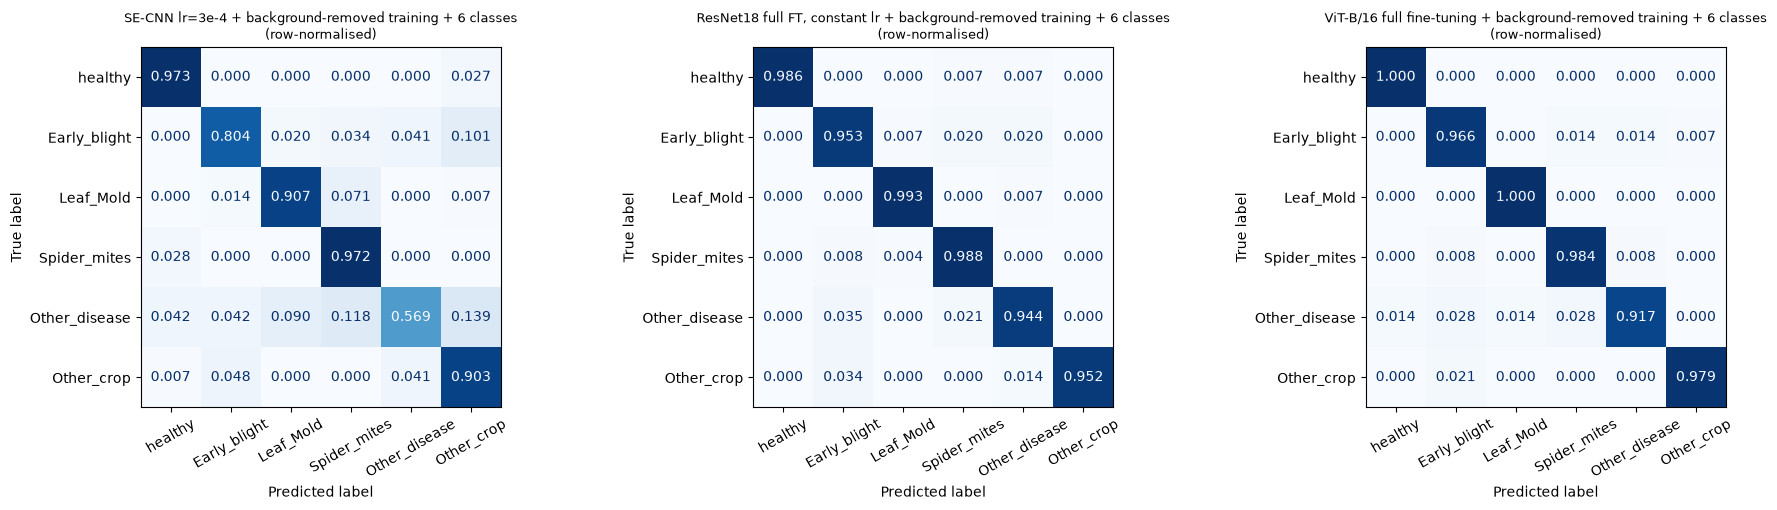

In [9]:
# Confusion matrices over the six classes (row-normalised)
fig, axes = plt.subplots(1, len(OPEN_MODELS), figsize=(6.2 * len(OPEN_MODELS), 5.2))
for ax, name in zip(axes, OPEN_MODELS, strict=True):
    ConfusionMatrixDisplay.from_predictions(
        np.tile(y6_test, len(TRAIN_CONFIG["seeds"])),
        np.concatenate([test6_probs[(name, s, TEST6)].argmax(1) for s in TRAIN_CONFIG["seeds"]]),
        labels=range(NUM_CLASSES),
        display_labels=CLASS_NAMES,
        normalize="true",
        values_format=".3f",
        cmap="Blues",
        colorbar=False,
        xticks_rotation=30,
        ax=ax,
    )
    ax.set_title(f"{name}\n(row-normalised)", fontsize=9)
finish("open_set_confusion.png")

In [10]:
# The same tomato test leaves as notebook 05. Matching input: background removed, also grayscale,
# darker, blurred and noisy. Mismatch: the original photo and the leaf on a background tile.
tv = make_test_variants(data)
add_background_tests(tv, verbose=False)
CLEAN = "background removed"
MATCHED = {CLEAN: tv.variants[CLEAN]} | {
    f"{CLEAN} + {change}": images
    for change, images in image_changes(tv.variants[CLEAN]).items()
}
MISMATCHED = {
    "original photo (with background)": tv.variants["original"],
    **tv.background_tests,
}
TESTS = MATCHED | MISMATCHED
CHANGES = [v for v in TESTS if v != CLEAN]
y_rob, DONOR_CLASS = tv.y, tv.donor_class

rob_probs = predict_probs(ALL_MODELS, TESTS)
rob_preds = {k: p.argmax(1) for k, p in rob_probs.items()}
# macro-F1 over the four tomato classes; a prediction into Other_disease / Other_crop is an error
rob_scores = {
    v: seed_scores(ALL_MODELS, rob_preds, v, y_rob, TOMATO_LABELS) for v in TESTS
}
other_share = {
    v: {
        n: np.array([(rob_preds[(n, s, v)] >= OTHER_DISEASE).mean() for s in TRAIN_CONFIG["seeds"]])
        for n in ALL_MODELS
    }
    for v in TESTS
}

clean = pd.DataFrame(
    {
        "4 classes": [mean_sd(rob_scores[CLEAN][b], 4) for _, b in PAIRS],
        "6 classes": [mean_sd(rob_scores[CLEAN][o], 4) for o, _ in PAIRS],
        "tomato photos called a new class (6 classes)": [
            mean_sd(other_share[CLEAN][o], 4) for o, _ in PAIRS
        ],
    },
    index=pd.Index(ARCHS, name="tomato test macro-F1"),
)
paired = comparison_table(PAIRS, rob_scores[CLEAN]).set_index(pd.Index(ARCHS))
clean["6 - 4 classes"] = paired["A - B (mean)"]
clean.to_csv(out_path("open_set_clean.csv"))
clean

Test images with a segmented version: 688 / 688


,4 classes,6 classes,tomato photos called a new class (6 classes),6 - 4 classes
tomato test macro-F1,,,,
SE-CNN,0.9669 ± 0.0000,0.9364 ± 0.0000,0.0378 ± 0.0000,-0.030503
ResNet18,0.9919 ± 0.0000,0.9844 ± 0.0000,0.0073 ± 0.0000,-0.007437
ViT-B/16,0.9959 ± 0.0000,0.9910 ± 0.0000,0.0073 ± 0.0000,-0.004885


## 26. Robustness on the Same Tomato Test Leaves

The tests of Sections 14 and 16 on the same 688 tomato test photos. The score is the macro-F1 over the four tomato classes; a prediction into a new class counts as an error.

| Test | Input |
|---|---|
| background removed + grayscale / darker (×0.6) / blur (σ = 2) / noise (σ = 20) | matching: the changes of Section 14 applied to the background-removed photo |
| original photo (with background) | **mismatch**: the photo as a phone would take it, without segmentation |
| same-class / other-class background | **mismatch**: the cut-out leaf on a background tile of a photo of its own / another class (Section 16) |

A six-class model has two more ways to be wrong, but it also learned from many more leaves. The second table gives the difference six-class minus four-class; the third shows how many tomato photos the six-class models send to the new classes.

In [11]:
robustness = pd.DataFrame(
    {v: [mean_sd(rob_scores[v][n], 3) for n in ALL_MODELS] for v in TESTS},
    index=pd.MultiIndex.from_tuples(
        [(DESIGN[n], n) for n in ALL_MODELS], names=["classes", "model"]
    ),
)
robustness.to_csv(out_path("open_set_robustness.csv"))
display(robustness)

robustness_comparison = (
    pd.concat(
        {v: comparison_table(PAIRS, rob_scores[v]) for v in TESTS}, names=["condition"]
    )
    .droplevel(1)[["model", "A - B (mean)"]]
    .rename(columns={"A - B (mean)": "6 - 4 classes"})
)
robustness_comparison.to_csv(out_path("open_set_robustness_comparison.csv"))
display(robustness_comparison.round(4))

other_table = pd.DataFrame(
    {v: [mean_sd(other_share[v][n], 3) for n in OPEN_MODELS] for v in TESTS},
    index=OPEN_MODELS,
)
other_table.to_csv(out_path("open_set_tomato_called_other.csv"))
other_table

background removed  \
classes   model                                                                   
4 classes SE-CNN lr=3e-4 + background-removed training            0.967 ± 0.000   
          ResNet18 full FT, constant lr + background-remo...      0.992 ± 0.000   
          ViT-B/16 full fine-tuning + background-removed ...      0.996 ± 0.000   
6 classes SE-CNN lr=3e-4 + background-removed training + ...      0.936 ± 0.000   
          ResNet18 full FT, constant lr + background-remo...      0.984 ± 0.000   
          ViT-B/16 full fine-tuning + background-removed ...      0.991 ± 0.000   

                                                             background removed + grayscale  \
classes   model                                                                               
4 classes SE-CNN lr=3e-4 + background-removed training                        0.208 ± 0.000   
          ResNet18 full FT, constant lr + background-remo...                  0.521 ± 0.000   
          ViT-B/16 full fine-tuning + background-removed ...                  0.668 ± 0.000   
6 classes SE-CNN lr=3e-4 + background-removed training + ...                  0.150 ± 0.000   
          ResNet18 full FT, constant lr + background-remo...                  0.414 ± 0.000   
          ViT-B/16 full fine-tuning + background-removed ...                  0.616 ± 0.000   

                                                             background removed + darker (x0.6)  \
classes   model                                                                                   
4 classes SE-CNN lr=3e-4 + background-removed training                            0.815 ± 0.000   
          ResNet18 full FT, constant lr + background-remo...                      0.987 ± 0.000   
          ViT-B/16 full fine-tuning + background-removed ...                      0.991 ± 0.000   
6 classes SE-CNN lr=3e-4 + background-removed training + ...                      0.510 ± 0.000   
          ResNet18 full FT, constant lr + background-remo...                      0.988 ± 0.000   
          ViT-B/16 full fine-tuning + background-removed ...                      0.991 ± 0.000   

                                                             background removed + blur (sigma=2)  \
classes   model                                                                                    
4 classes SE-CNN lr=3e-4 + background-removed training                             0.283 ± 0.000   
          ResNet18 full FT, constant lr + background-remo...                       0.349 ± 0.000   
          ViT-B/16 full fine-tuning + background-removed ...                       0.909 ± 0.000   
6 classes SE-CNN lr=3e-4 + background-removed training + ...                       0.209 ± 0.000   
          ResNet18 full FT, constant lr + background-remo...                       0.524 ± 0.000   
          ViT-B/16 full fine-tuning + background-removed ...                       0.787 ± 0.000   

                                                             background removed + noise (sigma=20)  \
classes   model                                                                                      
4 classes SE-CNN lr=3e-4 + background-removed training                               0.089 ± 0.000   
          ResNet18 full FT, constant lr + background-remo...                         0.783 ± 0.000   
          ViT-B/16 full fine-tuning + background-removed ...                         0.966 ± 0.000   
6 classes SE-CNN lr=3e-4 + background-removed training + ...                         0.000 ± 0.000   
          ResNet18 full FT, constant lr + background-remo...                         0.003 ± 0.000   
          ViT-B/16 full fine-tuning + background-removed ...                         0.973 ± 0.000   

                                                             original photo (with background)  \
classes   model                                                                                 
4 classes SE-CNN lr=3e-4 + bac

,model,6 - 4 classes
condition,,
background removed,SE-CNN lr=3e-4 + background-removed training +...,-0.0305
background removed,"ResNet18 full FT, constant lr + background-rem...",-0.0074
background removed,ViT-B/16 full fine-tuning + background-removed...,-0.0049
background removed + grayscale,SE-CNN lr=3e-4 + background-removed training +...,-0.0584
background removed + grayscale,"ResNet18 full FT, constant lr + background-rem...",-0.1072
background removed + grayscale,ViT-B/16 full fine-tuning + background-removed...,-0.0515
background removed + darker (x0.6),SE-CNN lr=3e-4 + background-removed training +...,-0.3047
background removed + darker (x0.6),"ResNet18 full FT, constant lr + background-rem...",0.0005
background removed + darker (x0.6),ViT-B/16 full fine-tuning + background-removed...,-0.0006


,background removed,background removed + grayscale,background removed + darker (x0.6),background removed + blur (sigma=2),background removed + noise (sigma=20),original photo (with background),same-class background,other-class background
SE-CNN lr=3e-4 + background-removed training + 6 classes,0.038 ± 0.000,0.064 ± 0.000,0.022 ± 0.000,0.837 ± 0.000,1.000 ± 0.000,0.163 ± 0.000,0.170 ± 0.000,0.121 ± 0.000
"ResNet18 full FT, constant lr + background-removed training + 6 classes",0.007 ± 0.000,0.625 ± 0.000,0.007 ± 0.000,0.340 ± 0.000,0.999 ± 0.000,0.400 ± 0.000,0.593 ± 0.000,0.645 ± 0.000
ViT-B/16 full fine-tuning + background-removed training + 6 classes,0.007 ± 0.000,0.140 ± 0.000,0.006 ± 0.000,0.124 ± 0.000,0.019 ± 0.000,0.045 ± 0.000,0.076 ± 0.000,0.102 ± 0.000


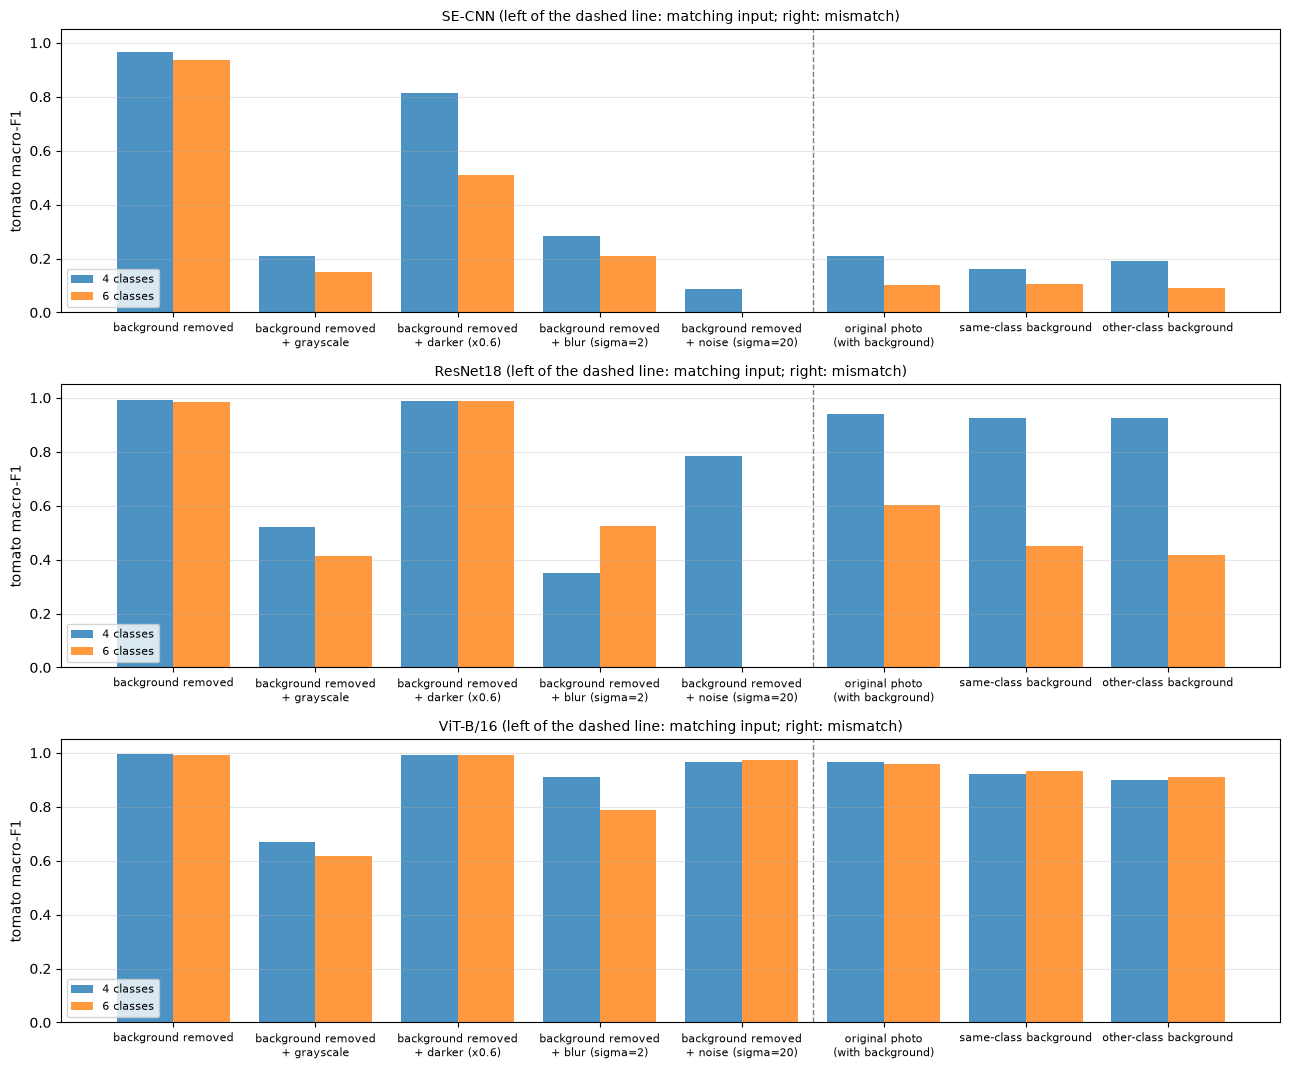

In [12]:
fig, axes = plt.subplots(len(ARCHS), 1, figsize=(13, 3.6 * len(ARCHS)), sharey=True)
labels = [v.replace(" + ", "\n+ ").replace(" (with", "\n(with") for v in TESTS]
for ax, arch, (open_name, base) in zip(axes, ARCHS, PAIRS, strict=True):
    group = [base, open_name]
    grouped_bars(
        ax,
        labels,
        ["4 classes", "6 classes"],
        [[rob_scores[v][n].mean() for v in TESTS] for n in group],
        alpha=0.8,
    )
    ax.axvline(len(MATCHED) - 0.5, color="grey", linestyle="--", linewidth=1)
    ax.set_title(
        f"{arch} (left of the dashed line: matching input; right: mismatch)",
        fontsize=10,
    )
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis="x", labelsize=8)
    ax.set_ylabel("tomato macro-F1")
    ax.grid(axis="y", alpha=0.3)
    ax.legend(loc="lower left", fontsize=8)
finish("open_set_robustness.png")

In [13]:
# Same leaf on another class's background: share of predictions = class of the leaf / of the background photo
condition = "other-class background"
following = pd.DataFrame(
    {
        column: [
            mean_sd([(rob_preds[(n, s, condition)] == target).mean() for s in TRAIN_CONFIG["seeds"]], 3)
            for n in ALL_MODELS
        ]
        for column, target in {
            "prediction = class of the leaf": y_rob,
            "prediction = class of the background photo": DONOR_CLASS[condition],
        }.items()
    }
    | {
        "prediction = a new class": [
            mean_sd(other_share[condition][n], 3) for n in ALL_MODELS
        ]
    },
    index=ALL_MODELS,
)
following.to_csv(out_path("open_set_background_following.csv"))
following

,prediction = class of the leaf,prediction = class of the background photo,prediction = a new class
SE-CNN lr=3e-4 + background-removed training,0.249 ± 0.000,0.199 ± 0.000,0.000 ± 0.000
"ResNet18 full FT, constant lr + background-removed training",0.924 ± 0.000,0.013 ± 0.000,0.000 ± 0.000
ViT-B/16 full fine-tuning + background-removed training,0.894 ± 0.000,0.035 ± 0.000,0.000 ± 0.000
SE-CNN lr=3e-4 + background-removed training + 6 classes,0.199 ± 0.000,0.195 ± 0.000,0.121 ± 0.000
"ResNet18 full FT, constant lr + background-removed training + 6 classes",0.330 ± 0.000,0.010 ± 0.000,0.645 ± 0.000
ViT-B/16 full fine-tuning + background-removed training + 6 classes,0.869 ± 0.000,0.009 ± 0.000,0.102 ± 0.000


## 27. Left-Out Series and Field Photos of the Tomato Classes

The tests of Section 19 for both designs. The healthy greenhouse series `GH_HL` has background-removed versions in PlantVillage and is tested on them (recall of healthy). The PlantDoc field photos of the four tomato classes have no segmented version, so they are a **mismatch** test on the photos as they are (macro-F1 over the classes present). A prediction into a new class counts as an error, and the share of such predictions is reported separately.

In [14]:
# Left-out series GH_HL (Section 19.1), background removed
SERIES_SEG, series_ok = load_segmented(data.other_df["path"], "other_series_segmented")
SERIES_SEG = SERIES_SEG[np.flatnonzero(series_ok)]
print(
    f"GH_HL photos with a background-removed version: {series_ok.sum()} of {len(series_ok)}"
)
TEST_IMAGES = SEG4[data.test_idx]
healthy = DATA_CONFIG["classes"].index("Tomato___healthy")

# PlantDoc photos of the four classes (Section 19.2), as they are
field_df = field_records(
    {PLANTDOC_CONFIG["folders"][c]: label for label, c in enumerate(DATA_CONFIG["classes"])}
)
FIELD_IMAGES = build_cache(field_df["path"], "field")  # the cache of notebook 05
y_field = field_df["label"].to_numpy()

shift_preds = {
    k: p.argmax(1)
    for k, p in predict_probs(
        ALL_MODELS, {"test": TEST_IMAGES, "series": SERIES_SEG, "field": FIELD_IMAGES}
    ).items()
}
series_recall = {
    n: np.array([(shift_preds[(n, s, "series")] == healthy).mean() for s in TRAIN_CONFIG["seeds"]])
    for n in ALL_MODELS
}
field_table, _, field_scores = shift_table(
    ALL_MODELS,
    shift_preds,
    "field",
    y=y_field,
    y_clean=data.y_test,
    columns=("clean test", "field photos"),
)


def called_other(name, set_name):
    return np.array(
        [(shift_preds[(name, s, set_name)] >= OTHER_DISEASE).mean() for s in TRAIN_CONFIG["seeds"]]
    )


series_field = pd.DataFrame(
    {
        "classes": [DESIGN[n] for n in ALL_MODELS],
        "GH_HL: healthy recall": [mean_sd(series_recall[n], 3) for n in ALL_MODELS],
        "GH_HL: called a new class": [
            mean_sd(called_other(n, "series"), 3) for n in ALL_MODELS
        ],
        "PlantDoc (mismatch): macro-F1": [
            mean_sd(field_scores[n], 3) for n in ALL_MODELS
        ],
        "PlantDoc (mismatch): called a new class": [
            mean_sd(called_other(n, "field"), 3) for n in ALL_MODELS
        ],
    },
    index=pd.Index(ALL_MODELS, name="model"),
)
series_field.to_csv(out_path("open_set_series_field.csv"))
series_field

GH_HL photos with a background-removed version: 590 of 590


,classes,GH_HL: healthy recall,GH_HL: called a new class,PlantDoc (mismatch): macro-F1,PlantDoc (mismatch): called a new class
model,,,,,
SE-CNN lr=3e-4 + background-removed training,4 classes,0.305 ± 0.000,0.000 ± 0.000,0.244 ± 0.000,0.000 ± 0.000
"ResNet18 full FT, constant lr + background-removed training",4 classes,0.936 ± 0.000,0.000 ± 0.000,0.215 ± 0.000,0.000 ± 0.000
ViT-B/16 full fine-tuning + background-removed training,4 classes,0.893 ± 0.000,0.000 ± 0.000,0.324 ± 0.000,0.000 ± 0.000
SE-CNN lr=3e-4 + background-removed training + 6 classes,6 classes,0.141 ± 0.000,0.664 ± 0.000,0.184 ± 0.000,0.344 ± 0.000
"ResNet18 full FT, constant lr + background-removed training + 6 classes",6 classes,0.088 ± 0.000,0.902 ± 0.000,0.216 ± 0.000,0.410 ± 0.000
ViT-B/16 full fine-tuning + background-removed training + 6 classes,6 classes,0.407 ± 0.000,0.593 ± 0.000,0.174 ± 0.000,0.693 ± 0.000


## 28. Out-of-Scope Photos: Does the Model Refuse Them?

A useful classifier should say "not one of my four classes" for a photo of another disease or another crop. We test these groups of such photos:

| Set | Photos | Input | Seen in training? |
|---|---|---|---|
| **test leaves of the new classes** | the test split of Other_disease and Other_crop | background removed | the same folders (other leaves) |
| **held-out tomato diseases** | late blight, mosaic virus (PlantVillage, 150 photos each) | background removed | no |
| **held-out crops** | blueberry, corn ×4, orange, raspberry, soybean, squash (PlantVillage, 150 each) | background removed | no |
| **PlantDoc, seen kinds / unseen kinds** | field photos of other tomato diseases and other crops, split by whether the disease or crop occurs in training | **mismatch**: as they are | partly / no |

**Rejection rule.** A four-class model can only refuse a photo by its confidence. A six-class model can also predict a new class. We use the same rule for both designs: a photo is *rejected* if the model predicts Other_disease or Other_crop, or if the probability of its most likely tomato class is below a threshold. The threshold of every model keeps 95% of the (background-removed) **tomato validation photos**, so the test photos play no part in choosing it. The *false rejections* are the tomato test photos that are rejected. The **AUROC** measures, without a threshold, how well 1 − (tomato confidence) separates the out-of-scope photos from the 688 tomato test photos (0.5 = chance, 1 = perfect). For the PlantDoc sets the tomato reference stays the background-removed test photos, so their AUROC mixes the mismatch with the out-of-scope question.

All the PlantDoc photos of the selected folders are used (train and test folders of the authors), as in Section 19.2.

In [15]:
held_df = held_out_records()
HELD_SEG = load_segmented(held_df["path"], "held_out_segmented")[0]
new_test = data6.test_idx[data6.labels[data6.test_idx].numpy() >= OTHER_DISEASE]
OUT_SETS = {
    "test leaves of the new classes": SEG6[new_test],
    "held-out tomato diseases": HELD_SEG[
        np.flatnonzero(held_df.label == OTHER_DISEASE)
    ],
    "held-out crops": HELD_SEG[np.flatnonzero(held_df.label == OTHER_CROP)],
}

# PlantDoc folders that downloaded completely (the sets are skipped if the download fails)
field_out_df = out_of_scope_field_records()
print(
    f"PlantDoc folders available: {field_out_df['folder'].nunique()} of {len(FIELD_FOLDERS)}"
)
FIELD_OUT_AVAILABLE = len(field_out_df) > 0
if FIELD_OUT_AVAILABLE:
    FIELD_OUT_IMAGES = build_cache(field_out_df["path"], "field_out_of_scope")
    seen_kind = np.array(field_out_df["seen kind"], dtype=bool)
    OUT_SETS["PlantDoc, seen kinds"] = FIELD_OUT_IMAGES[np.flatnonzero(seen_kind)]
    OUT_SETS["PlantDoc, unseen kinds"] = FIELD_OUT_IMAGES[np.flatnonzero(~seen_kind)]
print({k: len(v) for k, v in OUT_SETS.items()})

out_probs = predict_probs(
    ALL_MODELS,
    {"tomato validation": SEG4[data.val_idx], "test": TEST_IMAGES, **OUT_SETS},
)
threshold = {
    (n, s): rejection_threshold(out_probs[(n, s, "tomato validation")])
    for n in ALL_MODELS
    for s in TRAIN_CONFIG["seeds"]
}


def seed_array(fn):
    # {model: array over the seeds} of fn(model, seed)
    return {n: np.array([fn(n, s) for s in TRAIN_CONFIG["seeds"]]) for n in ALL_MODELS}


rej = {
    v: seed_array(
        lambda n, s, v=v: rejected(out_probs[(n, s, v)], threshold[(n, s)]).mean()
    )
    for v in OUT_SETS
}
auc = {
    v: seed_array(
        lambda n, s, v=v: out_of_scope_auroc(
            out_probs[(n, s, "test")], out_probs[(n, s, v)]
        )
    )
    for v in OUT_SETS
}
false_rej = seed_array(
    lambda n, s: rejected(out_probs[(n, s, "test")], threshold[(n, s)]).mean()
)

index = pd.MultiIndex.from_tuples(
    [(DESIGN[n], n) for n in ALL_MODELS], names=["classes", "model"]
)
rejection = pd.DataFrame(
    {"tomato test: falsely rejected": [mean_sd(false_rej[n], 3) for n in ALL_MODELS]}
    | {v: [mean_sd(rej[v][n], 3) for n in ALL_MODELS] for v in OUT_SETS},
    index=index,
)
rejection.to_csv(out_path("open_set_rejection.csv"))
auroc = pd.DataFrame(
    {v: [mean_sd(auc[v][n], 3) for n in ALL_MODELS] for v in OUT_SETS}, index=index
)
auroc.to_csv(out_path("open_set_auroc.csv"))
display(rejection)
auroc

PlantDoc folders available: 48 of 48 (train and test)
{'test leaves of the new classes': 289, 'held-out tomato diseases': 300, 'held-out crops': 1350, 'PlantDoc, seen kinds': 1359, 'PlantDoc, unseen kinds': 969}


tomato test: falsely rejected  \
classes   model                                                                              
4 classes SE-CNN lr=3e-4 + background-removed training                       0.062 ± 0.000   
          ResNet18 full FT, constant lr + background-remo...                 0.065 ± 0.000   
          ViT-B/16 full fine-tuning + background-removed ...                 0.064 ± 0.000   
6 classes SE-CNN lr=3e-4 + background-removed training + ...                 0.070 ± 0.000   
          ResNet18 full FT, constant lr + background-remo...                 0.047 ± 0.000   
          ViT-B/16 full fine-tuning + background-removed ...                 0.049 ± 0.000   

                                                             test leaves of the new classes  \
classes   model                                                                               
4 classes SE-CNN lr=3e-4 + background-removed training                        0.218 ± 0.000   
          ResNet18 full FT, constant lr + background-remo...                  0.422 ± 0.000   
          ViT-B/16 full fine-tuning + background-removed ...                  0.567 ± 0.000   
6 classes SE-CNN lr=3e-4 + background-removed training + ...                  0.872 ± 0.000   
          ResNet18 full FT, constant lr + background-remo...                  0.972 ± 0.000   
          ViT-B/16 full fine-tuning + background-removed ...                  0.997 ± 0.000   

                                                             held-out tomato diseases  \
classes   model                                                                         
4 classes SE-CNN lr=3e-4 + background-removed training                  0.287 ± 0.000   
          ResNet18 full FT, constant lr + background-remo...            0.560 ± 0.000   
          ViT-B/16 full fine-tuning + background-removed ...            0.560 ± 0.000   
6 classes SE-CNN lr=3e-4 + background-removed training + ...            0.333 ± 0.000   
          ResNet18 full FT, constant lr + background-remo...            0.680 ± 0.000   
          ViT-B/16 full fine-tuning + background-removed ...            0.823 ± 0.000   

                                                             held-out crops  \
classes   model                                                               
4 classes SE-CNN lr=3e-4 + background-removed training        0.256 ± 0.000   
          ResNet18 full FT, constant lr + background-remo...  0.641 ± 0.000   
          ViT-B/16 full fine-tuning + background-removed ...  0.867 ± 0.000   
6 classes SE-CNN lr=3e-4 + background-removed training + ...  0.850 ± 0.000   
          ResNet18 full FT, constant lr + background-remo...  0.988 ± 0.000   
          ViT-B/16 full fine-tuning + background-removed ...  0.999 ± 0.000   

                                                             PlantDoc, seen kinds  \
classes   model                                                                     
4 classes SE-CNN lr=3e-4 + background-removed training              0.079 ± 0.000   
          ResNet18 full FT, constant lr + background-remo...        0.213 ± 0.000   
          ViT-B/16 full fine-tuning + background-removed ...        0.729 ± 0.000   
6 classes SE-CNN lr=3e-4 + background-removed training + ...        0.354 ± 0.000   
          ResNet18 full FT, constant lr + background-remo...        0.915 ± 0.000   
          ViT-B/16 full fine-tuning + background-removed ...        0.988 ± 0.000   

                                                             PlantDoc, unseen kinds  
classes   model                                                                      
4 classes SE-CNN lr=3e-4 + background-removed training                0.109 ± 0.000  
          ResNet18 full FT, constant lr + background-remo...          0.250 ± 0.000  
          ViT-B/16 full fine-tuning + background-removed ...          0.842 ± 0.000  
6 classes SE-CNN lr=3e-4 + background-removed training + ...          0.335 ± 0.000  
    

test leaves of the new classes  \
classes   model                                                                               
4 classes SE-CNN lr=3e-4 + background-removed training                        0.627 ± 0.000   
          ResNet18 full FT, constant lr + background-remo...                  0.674 ± 0.000   
          ViT-B/16 full fine-tuning + background-removed ...                  0.867 ± 0.000   
6 classes SE-CNN lr=3e-4 + background-removed training + ...                  0.961 ± 0.000   
          ResNet18 full FT, constant lr + background-remo...                  0.996 ± 0.000   
          ViT-B/16 full fine-tuning + background-removed ...                  0.998 ± 0.000   

                                                             held-out tomato diseases  \
classes   model                                                                         
4 classes SE-CNN lr=3e-4 + background-removed training                  0.708 ± 0.000   
          ResNet18 full FT, constant lr + background-remo...            0.867 ± 0.000   
          ViT-B/16 full fine-tuning + background-removed ...            0.881 ± 0.000   
6 classes SE-CNN lr=3e-4 + background-removed training + ...            0.792 ± 0.000   
          ResNet18 full FT, constant lr + background-remo...            0.931 ± 0.000   
          ViT-B/16 full fine-tuning + background-removed ...            0.960 ± 0.000   

                                                             held-out crops  \
classes   model                                                               
4 classes SE-CNN lr=3e-4 + background-removed training        0.669 ± 0.000   
          ResNet18 full FT, constant lr + background-remo...  0.821 ± 0.000   
          ViT-B/16 full fine-tuning + background-removed ...  0.968 ± 0.000   
6 classes SE-CNN lr=3e-4 + background-removed training + ...  0.949 ± 0.000   
          ResNet18 full FT, constant lr + background-remo...  0.997 ± 0.000   
          ViT-B/16 full fine-tuning + background-removed ...  1.000 ± 0.000   

                                                             PlantDoc, seen kinds  \
classes   model                                                                     
4 classes SE-CNN lr=3e-4 + background-removed training              0.292 ± 0.000   
          ResNet18 full FT, constant lr + background-remo...        0.466 ± 0.000   
          ViT-B/16 full fine-tuning + background-removed ...        0.935 ± 0.000   
6 classes SE-CNN lr=3e-4 + background-removed training + ...        0.539 ± 0.000   
          ResNet18 full FT, constant lr + background-remo...        0.976 ± 0.000   
          ViT-B/16 full fine-tuning + background-removed ...        0.997 ± 0.000   

                                                             PlantDoc, unseen kinds  
classes   model                                                                      
4 classes SE-CNN lr=3e-4 + background-removed training                0.388 ± 0.000  
          ResNet18 full FT, constant lr + background-remo...          0.528 ± 0.000  
          ViT-B/16 full fine-tuning + background-removed ...          0.960 ± 0.000  
6 classes SE-CNN lr=3e-4 + background-removed training + ...          0.541 ± 0.000  
          ResNet18 full FT, constant lr + background-remo...          0.979 ± 0.000  
          ViT-B/16 full fine-tuning + background-removed ...          0.997 ± 0.000

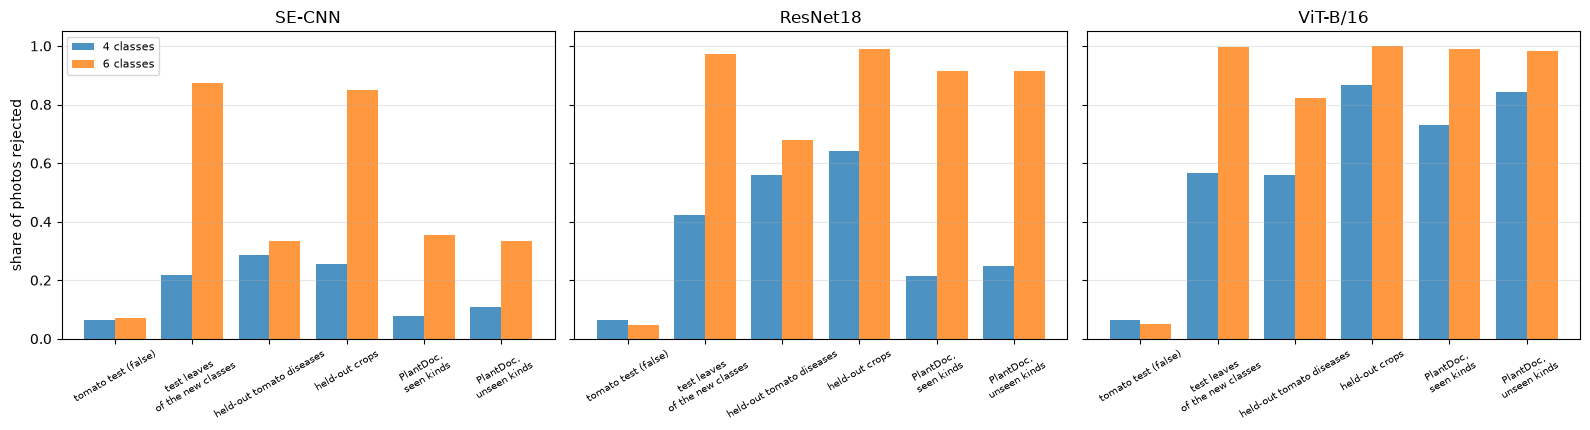

In [16]:
fig, axes = plt.subplots(1, len(ARCHS), figsize=(16, 4.4), sharey=True)
set_names = ["tomato test (false)", *OUT_SETS]
for ax, arch, (open_name, base) in zip(axes, ARCHS, PAIRS, strict=True):
    group = [base, open_name]
    values = [[false_rej[n], *[rej[v][n] for v in OUT_SETS]] for n in group]
    grouped_bars(
        ax,
        [s.replace(", ", ",\n").replace(" of the", "\nof the") for s in set_names],
        ["4 classes", "6 classes"],
        [[v.mean() for v in vals] for vals in values],
        alpha=0.8,
    )
    ax.set_title(arch)
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis="x", labelsize=7, labelrotation=30)
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("share of photos rejected")
axes[0].legend(loc="upper left", fontsize=8)
finish("open_set_rejection.png")

In [17]:
# Where do the held-out PlantVillage folders go? Share of predictions per class
HELD = "held-out (all)"
held_probs = predict_probs(ALL_MODELS, {HELD: HELD_SEG})
rows = []
for name in ALL_MODELS:
    probs = np.concatenate([held_probs[(name, s, HELD)] for s in TRAIN_CONFIG["seeds"]])
    rej_all = np.concatenate(
        [rejected(held_probs[(name, s, HELD)], threshold[(name, s)]) for s in TRAIN_CONFIG["seeds"]]
    )
    folders = np.tile(held_df["folder"].to_numpy(), len(TRAIN_CONFIG["seeds"]))
    pred = probs.argmax(1)
    for folder in held_df["folder"].unique():
        here = folders == folder
        rows.append(
            {
                "model": name,
                "folder": folder,
                **{c: (pred[here] == k).mean() for k, c in enumerate(CLASS_NAMES)},
                "rejected": rej_all[here].mean(),
            }
        )
held_out_folders = pd.DataFrame(rows).set_index(["model", "folder"])
held_out_folders.to_csv(out_path("open_set_held_out_folders.csv"))
display(held_out_folders["rejected"].unstack(0)[ALL_MODELS].round(3))
held_out_folders.loc[OPEN_MODELS].round(2)

model,SE-CNN lr=3e-4 + background-removed training,"ResNet18 full FT, constant lr + background-removed training",ViT-B/16 full fine-tuning + background-removed training,SE-CNN lr=3e-4 + background-removed training + 6 classes,"ResNet18 full FT, constant lr + background-removed training + 6 classes",ViT-B/16 full fine-tuning + background-removed training + 6 classes
folder,,,,,,
Blueberry___healthy,0.173,0.940,0.933,0.787,1.000,1.000
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,0.107,0.507,0.853,0.713,0.980,1.000
Corn_(maize)___Common_rust_,0.133,0.007,0.880,0.953,1.000,1.000
Corn_(maize)___Northern_Leaf_Blight,0.067,0.333,0.633,0.893,0.993,1.000
Corn_(maize)___healthy,0.120,0.787,0.933,0.587,1.000,1.000
Orange___Haunglongbing_(Citrus_greening),0.287,0.840,0.900,0.960,0.947,1.000
Raspberry___healthy,0.427,0.813,0.920,0.800,1.000,1.000
Soybean___healthy,0.633,0.767,0.820,0.980,1.000,1.000
Squash___Powdery_mildew,0.360,0.780,0.927,0.980,0.973,0.993


healthy  \
model                                              folder                                                        
SE-CNN lr=3e-4 + background-removed training + ... Tomato___Late_blight                                   0.00   
                                                   Tomato___Tomato_mosaic_virus                           0.00   
                                                   Blueberry___healthy                                    0.00   
                                                   Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.00   
                                                   Corn_(maize)___Common_rust_                            0.00   
                                                   Corn_(maize)___Northern_Leaf_Blight                    0.00   
                                                   Corn_(maize)___healthy                                 0.00   
                                                   Orange___Haunglongbing_(Citrus_greening)               0.00   
                                                   Raspberry___healthy                                    0.10   
                                                   Soybean___healthy                                      0.00   
                                                   Squash___Powdery_mildew                                0.00   
ResNet18 full FT, constant lr + background-remo... Tomato___Late_blight                                   0.00   
                                                   Tomato___Tomato_mosaic_virus                           0.00   
                                                   Blueberry___healthy                                    0.01   
                                                   Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.00   
                                                   Corn_(maize)___Common_rust_                            0.00   
                                                   Corn_(maize)___Northern_Leaf_Blight                    0.00   
                                                   Corn_(maize)___healthy                                 0.00   
                                                   Orange___Haunglongbing_(Citrus_greening)               0.00   
                                                   Raspberry___healthy                                    0.00   
                                                   Soybean___healthy                                      0.00   
                                                   Squash___Powdery_mildew                                0.05   
ViT-B/16 full fine-tuning + background-removed ... Tomato___Late_blight                                   0.08   
                                                   Tomato___Tomato_mosaic_virus                           0.00   
                                                   Blueberry___healthy                                    0.00   
                                                   Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.00   
                                                   Corn_(maize)___Common_rust_                            0.00   
                                                   Corn_(maize)___Northern_Leaf_Blight                    0.01   
                                                   Corn_(maize)___healthy                                 0.00   
                                                   Orange___Haunglongbing_(Citrus_greening)               0.00   
                                                   Raspberry___healthy                                    0.00   
                                                   Soybean___healthy                                      0.00   
                                                   Squash___Powdery_mildew                                0.09   

                                                                                                       Early_bli

## 29. Rejection Under Image Changes, and Calibration

A phone photo may also be darker, blurred or noisy. The changes of Section 14 are applied to the background-removed out-of-scope PlantVillage photos (the test leaves of the new classes and the held-out folders) and to the background-removed tomato test leaves. The threshold stays the one of the clean tomato validation photos. A model that rejects the changed out-of-scope photos but also rejects most changed tomato photos has not learned what is out of scope; the AUROC shows the separation of the two.

The second table gives the expected calibration error (ECE) on the tomato test leaves (Section 20): the gap between confidence and accuracy, where a prediction into a new class counts as wrong.

In [18]:
OUT_PV = torch.cat([OUT_SETS["test leaves of the new classes"], HELD_SEG])
changed_out = image_changes(OUT_PV)
rows = []
for change, images in changed_out.items():
    probs = predict_probs(
        ALL_MODELS, {"tomato": TESTS[f"{CLEAN} + {change}"], "out of scope": images}
    )
    for n in ALL_MODELS:
        per_seed = np.array(
            [
                [
                    rejected(probs[(n, s, "out of scope")], threshold[(n, s)]).mean(),
                    rejected(probs[(n, s, "tomato")], threshold[(n, s)]).mean(),
                    out_of_scope_auroc(
                        probs[(n, s, "tomato")], probs[(n, s, "out of scope")]
                    ),
                ]
                for s in TRAIN_CONFIG["seeds"]
            ]
        )
        rows.append(
            {
                "change": change,
                "classes": DESIGN[n],
                "model": n,
                "out of scope: rejected": mean_sd(per_seed[:, 0], 3),
                "tomato: falsely rejected": mean_sd(per_seed[:, 1], 3),
                "AUROC": mean_sd(per_seed[:, 2], 3),
            }
        )
del changed_out
rejection_changes = pd.DataFrame(rows).set_index(["change", "classes", "model"])
rejection_changes.to_csv(out_path("open_set_rejection_changes.csv"))
rejection_changes

out of scope: rejected  \
change           classes   model                                                                       
grayscale        4 classes SE-CNN lr=3e-4 + background-removed training                0.279 ± 0.000   
                           ResNet18 full FT, constant lr + background-remo...          0.818 ± 0.000   
                           ViT-B/16 full fine-tuning + background-removed ...          0.917 ± 0.000   
                 6 classes SE-CNN lr=3e-4 + background-removed training + ...          0.084 ± 0.000   
                           ResNet18 full FT, constant lr + background-remo...          0.991 ± 0.000   
                           ViT-B/16 full fine-tuning + background-removed ...          0.996 ± 0.000   
darker (x0.6)    4 classes SE-CNN lr=3e-4 + background-removed training                0.266 ± 0.000   
                           ResNet18 full FT, constant lr + background-remo...          0.583 ± 0.000   
                           ViT-B/16 full fine-tuning + background-removed ...          0.810 ± 0.000   
                 6 classes SE-CNN lr=3e-4 + background-removed training + ...          0.520 ± 0.000   
                           ResNet18 full FT, constant lr + background-remo...          0.931 ± 0.000   
                           ViT-B/16 full fine-tuning + background-removed ...          0.968 ± 0.000   
blur (sigma=2)   4 classes SE-CNN lr=3e-4 + background-removed training                0.195 ± 0.000   
                           ResNet18 full FT, constant lr + background-remo...          0.615 ± 0.000   
                           ViT-B/16 full fine-tuning + background-removed ...          0.833 ± 0.000   
                 6 classes SE-CNN lr=3e-4 + background-removed training + ...          0.936 ± 0.000   
                           ResNet18 full FT, constant lr + background-remo...          0.953 ± 0.000   
                           ViT-B/16 full fine-tuning + background-removed ...          0.971 ± 0.000   
noise (sigma=20) 4 classes SE-CNN lr=3e-4 + background-removed training                0.018 ± 0.000   
                           ResNet18 full FT, constant lr + background-remo...          0.838 ± 0.000   
                           ViT-B/16 full fine-tuning + background-removed ...          0.786 ± 0.000   
                 6 classes SE-CNN lr=3e-4 + background-removed training + ...          1.000 ± 0.000   
                           ResNet18 full FT, constant lr + background-remo...          1.000 ± 0.000   
                           ViT-B/16 full fine-tuning + background-removed ...          0.971 ± 0.000   

                                                                              tomato: falsely rejected  \
change           classes   model                                                                         
grayscale        4 classes SE-CNN lr=3e-4 + background-removed training                  0.593 ± 0.000   
                           ResNet18 full FT, constant lr + background-remo...            0.798 ± 0.000   
                           ViT-B/16 full fine-tuning + background-removed ...            0.724 ± 0.000   
                 6 classes SE-CNN lr=3e-4 + background-removed training + ...            0.106 ± 0.000   
                           ResNet18 full FT, constant lr + background-remo...            0.917 ± 0.000   
                           ViT-B/16 full fine-tuning + background-removed ...            0.772 ± 0.000   
darker (x0.6)    4 classes SE-CNN lr=3e-4 + background-removed training                  0.285 ± 0.000   
                           ResNet18 full FT, constant lr + background-remo...            0.073 ± 0.000   
                           ViT-B/16 full fine-tuning + background-removed ...            0.080 ± 0.000   
                 6 classes SE-CNN lr=3e-4 + background-removed training + ...            0.145 ± 0.000   
                           ResNet18 full FT, constant lr + background-remo...            0.047 ± 0.00

In [19]:
ECE_TESTS = [*MATCHED, "original photo (with background)"]
ece = pd.DataFrame(
    {
        v: [
            np.mean(
                [expected_calibration_error(rob_probs[(n, s, v)], y_rob) for s in TRAIN_CONFIG["seeds"]]
            )
            for n in ALL_MODELS
        ]
        for v in ECE_TESTS
    },
    index=index,
)
ece.to_csv(out_path("open_set_calibration.csv"))
ece.round(3)

background removed  \
classes   model                                                                    
4 classes SE-CNN lr=3e-4 + background-removed training                     0.018   
          ResNet18 full FT, constant lr + background-remo...               0.005   
          ViT-B/16 full fine-tuning + background-removed ...               0.005   
6 classes SE-CNN lr=3e-4 + background-removed training + ...               0.046   
          ResNet18 full FT, constant lr + background-remo...               0.011   
          ViT-B/16 full fine-tuning + background-removed ...               0.009   

                                                              background removed + grayscale  \
classes   model                                                                                
4 classes SE-CNN lr=3e-4 + background-removed training                                 0.457   
          ResNet18 full FT, constant lr + background-remo...                           0.338   
          ViT-B/16 full fine-tuning + background-removed ...                           0.217   
6 classes SE-CNN lr=3e-4 + background-removed training + ...                           0.639   
          ResNet18 full FT, constant lr + background-remo...                           0.444   
          ViT-B/16 full fine-tuning + background-removed ...                           0.267   

                                                              background removed + darker (x0.6)  \
classes   model                                                                                    
4 classes SE-CNN lr=3e-4 + background-removed training                                     0.044   
          ResNet18 full FT, constant lr + background-remo...                               0.007   
          ViT-B/16 full fine-tuning + background-removed ...                               0.004   
6 classes SE-CNN lr=3e-4 + background-removed training + ...                               0.258   
          ResNet18 full FT, constant lr + background-remo...                               0.007   
          ViT-B/16 full fine-tuning + background-removed ...                               0.011   

                                                              background removed + blur (sigma=2)  \
classes   model                                                                                     
4 classes SE-CNN lr=3e-4 + background-removed training                                      0.499   
          ResNet18 full FT, constant lr + background-remo...                                0.506   
          ViT-B/16 full fine-tuning + background-removed ...                                0.038   
6 classes SE-CNN lr=3e-4 + background-removed training + ...                                0.715   
          ResNet18 full FT, constant lr + background-remo...                                0.327   
          ViT-B/16 full fine-tuning + background-removed ...                                0.175   

                                                              background removed + noise (sigma=20)  \
classes   model                                                                                       
4 classes SE-CNN lr=3e-4 + background-removed training                                        0.785   
          ResNet18 full FT, constant lr + background-remo...                                  0.056   
          ViT-B/16 full fine-tuning + background-removed ...                                  0.024   
6 classes SE-CNN lr=3e-4 + background-removed training + ...                                  1.000   
          ResNet18 full FT, constant lr + background-remo...                                  0.993   
          ViT-B/16 full fine-tuning + background-removed ...                                  0.027   

                                                              original photo (with background)  
classes   model                                                                         

## 30. Summary

One row per recipe and design (seed 62, background-removed training). *Changes* is the mean tomato macro-F1 over the four changes of the background-removed photos (grayscale, darker, blur, noise). *Original photo* and *PlantDoc* are mismatch tests. *Rejected* uses the rule of Section 28, and *held-out* pools the held-out tomato diseases and crops.

In [20]:
held_rej = seed_array(
    lambda n, s: rejected(held_probs[(n, s, HELD)], threshold[(n, s)]).mean()
)
matched_changes = [v for v in MATCHED if v != CLEAN]
columns = {
    "tomato test macro-F1": rob_scores[CLEAN],
    "changes (mean macro-F1)": {
        n: np.mean([rob_scores[v][n] for v in matched_changes], 0) for n in ALL_MODELS
    },
    "original photo (with background)": rob_scores["original photo (with background)"],
    "other-class background": rob_scores["other-class background"],
    "GH_HL healthy recall": series_recall,
    "PlantDoc macro-F1": field_scores,
    "tomato falsely rejected": false_rej,
    "rejected: new-class test leaves": rej["test leaves of the new classes"],
    "rejected: held-out": held_rej,
    "AUROC: held-out tomato diseases": auc["held-out tomato diseases"],
    "AUROC: held-out crops": auc["held-out crops"],
}
if FIELD_OUT_AVAILABLE:
    n_seen = int(seen_kind.sum())
    # both PlantDoc sets, weighted by their number of photos
    columns["rejected: PlantDoc out of scope"] = {
        n: (
            n_seen * rej["PlantDoc, seen kinds"][n]
            + (len(seen_kind) - n_seen) * rej["PlantDoc, unseen kinds"][n]
        )
        / len(seen_kind)
        for n in ALL_MODELS
    }
summary = pd.DataFrame(
    {c: [np.mean(scores[n]) for n in ALL_MODELS] for c, scores in columns.items()},
    index=index,
)
summary.to_csv(out_path("open_set_summary.csv"))
summary.T.round(3)

classes                                                             4 classes  \
model                            SE-CNN lr=3e-4 + background-removed training   
tomato test macro-F1                                                    0.967   
changes (mean macro-F1)                                                 0.349   
original photo (with background)                                        0.209   
other-class background                                                  0.192   
GH_HL healthy recall                                                    0.305   
PlantDoc macro-F1                                                       0.244   
tomato falsely rejected                                                 0.062   
rejected: new-class test leaves                                         0.218   
rejected: held-out                                                      0.262   
AUROC: held-out tomato diseases                                         0.708   
AUROC: held-out crops                                                   0.669   
rejected: PlantDoc out of scope                                         0.091   

classes                                                                                       \
model                            ResNet18 full FT, constant lr + background-removed training   
tomato test macro-F1                                                          0.992            
changes (mean macro-F1)                                                       0.660            
original photo (with background)                                              0.939            
other-class background                                                        0.925            
GH_HL healthy recall                                                          0.936            
PlantDoc macro-F1                                                             0.215            
tomato falsely rejected                                                       0.065            
rejected: new-class test leaves                                               0.422            
rejected: held-out                                                            0.627            
AUROC: held-out tomato diseases                                               0.867            
AUROC: held-out crops                                                         0.821            
rejected: PlantDoc out of scope                                               0.229            

classes                                                                                   \
model                            ViT-B/16 full fine-tuning + background-removed training   
tomato test macro-F1                                                          0.996        
changes (mean macro-F1)                                                       0.883        
original photo (with background)                                              0.965        
other-class background                                                        0.899        
GH_HL healthy recall                                                          0.893        
PlantDoc macro-F1                                                             0.324        
tomato falsely rejected                                                       0.064        
rejected: new-class test leaves                                               0.567        
rejected: held-out                                                            0.811        
AUROC: held-out tomato diseases                                               0.881        
AUROC: held-out crops                                                         0.968        
rejected: PlantDoc out of scope                                               0.776        

classes                                                                         6 classes  \
model                            SE-CNN lr=3e-4 + background-removed training + 6 classes   
tomato test macro-F1                         

### Discussion

*Written from the tables above after the run.*